# Chương 4 — Đồ thị 02: Boxplot ejection_fraction

**Võ Minh Huy — 2311110117**

Vẽ bằng Python từ bản after_Python trên đủ 299 hồ sơ. Không cần nhãn DEATH_EVENT. Hộp từ Q1 đến Q3, đường giữa là median, râu theo quy tắc 1,5×IQR. Điểm ngoài râu là ngoại lệ thống kê, không tự động kết luận là lỗi dữ liệu.

In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
ef = pd.to_numeric(du_lieu["ejection_fraction"], errors="raise")
if len(ef) != 299 or ef.isna().any() or not ef.between(0, 100).all():
    raise ValueError("Cần đủ 299 giá trị EF trong miền phần trăm.")
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/02_boxplot_ef"
thu_muc_kq.mkdir(parents=True, exist_ok=True)
q1, median, q3 = ef.quantile([0.25, 0.5, 0.75], interpolation="linear")
iqr = q3 - q1
can_duoi, can_tren = q1 - 1.5*iqr, q3 + 1.5*iqr
trong_can = ef.between(can_duoi, can_tren)
rau_duoi, rau_tren = ef[trong_can].min(), ef[trong_can].max()
ngoai_le = du_lieu.loc[~trong_can, ["MaHoSo", "ejection_fraction"]].copy()
thong_ke = pd.DataFrame({"SoHoSo":[len(ef)], "Min":[ef.min()], "Q1":[q1],
    "Median":[median], "Q3":[q3], "Max":[ef.max()], "Mean":[ef.mean()],
    "IQR":[iqr], "CanDuoi":[can_duoi], "CanTren":[can_tren],
    "RauDuoi":[rau_duoi], "RauTren":[rau_tren], "SoNgoaiLe":[len(ngoai_le)]})
thong_ke.round(2)

,SoHoSo,Min,Q1,Median,Q3,Max,Mean,IQR,CanDuoi,CanTren,RauDuoi,RauTren,SoNgoaiLe
0,299,14.0,30.0,38.0,45.0,80.0,38.08,15.0,7.5,67.5,14.0,65.0,2


In [2]:
ngoai_le.sort_values("ejection_fraction").reset_index(drop=True)

,MaHoSo,ejection_fraction
0,218,70.0
1,65,80.0


## Vẽ boxplot

Râu kéo tới giá trị quan sát xa nhất còn trong cận IQR, không kéo thẳng đến cận lý thuyết. Giữ các điểm ngoài râu trên đồ thị. Dấu hình thoi thể hiện mean, đường ngang trong hộp thể hiện median.

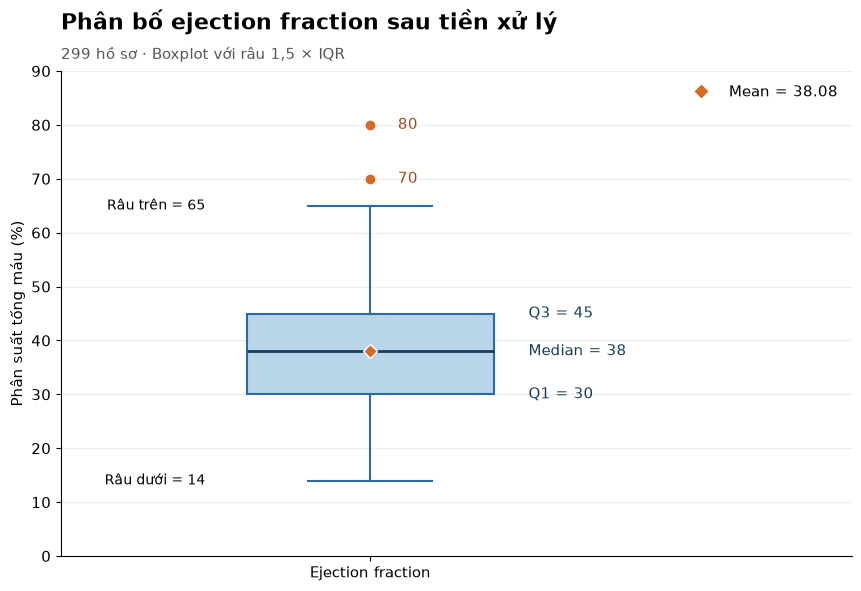

In [3]:
from matplotlib.lines import Line2D

plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11})
fig, ax = plt.subplots(figsize=(8.5, 5.8), layout="constrained")
box = ax.boxplot(ef.to_numpy(), whis=1.5, widths=0.36, showmeans=True, patch_artist=True,
    boxprops={"facecolor":"#B9D5EA", "edgecolor":"#2D6A9F", "linewidth":1.5},
    medianprops={"color":"#173C5B", "linewidth":2},
    meanprops={"marker":"D", "markerfacecolor":"#D46A24", "markeredgecolor":"white", "markersize":7},
    whiskerprops={"color":"#2D6A9F", "linewidth":1.5},
    capprops={"color":"#2D6A9F", "linewidth":1.5},
    flierprops={"marker":"o", "markerfacecolor":"#D46A24", "markeredgecolor":"#D46A24", "markersize":6})
# Kiểm tra hình vẽ thực sự dùng đúng số liệu và râu đã tính.
assert np.isclose(box["medians"][0].get_ydata()[0], median)
assert np.isclose(box["whiskers"][0].get_ydata()[-1], rau_duoi)
assert np.isclose(box["whiskers"][1].get_ydata()[-1], rau_tren)
assert len(box["fliers"][0].get_ydata()) == len(ngoai_le)
ax.set_title("Phân bố ejection fraction sau tiền xử lý", loc="left", fontsize=16, fontweight="bold", pad=30)
ax.text(0, 1.025, "299 hồ sơ · Boxplot với râu 1,5 × IQR", transform=ax.transAxes, color="#555555")
ax.set_ylabel("Phân suất tống máu (%)")
ax.set_xticks([1], ["Ejection fraction"])
ax.set_xlim(0.55, 1.7)
ax.set_ylim(0, 90)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.22)
ax.spines[["top", "right"]].set_visible(False)
for value, label in [(q1, "Q1"), (median, "Median"), (q3, "Q3")]:
    ax.text(1.23, value, f"{label} = {value:g}", va="center", color="#173C5B")
for value in sorted(ngoai_le["ejection_fraction"].unique()):
    ax.text(1.04, value, f"{value:g}", va="center", color="#A34B16")
ax.text(0.76, rau_duoi, f"Râu dưới = {rau_duoi:g}", ha="right", va="center", fontsize=10)
ax.text(0.76, rau_tren, f"Râu trên = {rau_tren:g}", ha="right", va="center", fontsize=10)
ax.legend(handles=[Line2D([], [], marker="D", linestyle="", color="#D46A24",
    label=f"Mean = {ef.mean():.2f}")], frameon=False, loc="upper right")
file_hinh = thu_muc_kq / "02_boxplot_ef.png"
fig.savefig(file_hinh, dpi=300, facecolor="white", bbox_inches="tight")
thong_ke.to_csv(thu_muc_kq / "thong_ke_python.csv", index=False, encoding="utf-8-sig")
ngoai_le.to_csv(thu_muc_kq / "ngoai_le_python.csv", index=False, encoding="utf-8-sig")
plt.show()

## Nhận xét

- Median là 38%; Q1=30% và Q3=45%, nên 50% phần giữa của dữ liệu nằm trong khoảng 30–45%.
- IQR=15; cận lý thuyết là 7,5 và 67,5. Hai râu thực tế ở 14 và 65.
- Có hai điểm ngoài râu ở 70 và 80; đây là ngoại lệ thống kê theo IQR. Giữ chúng trên hình và trong dữ liệu.
- Mean khoảng 38,08%, gần median 38%. Boxplot mô tả bản dữ liệu sau tiền xử lý, có cả giá trị EF đã thay theo quy tắc N07; không dùng riêng hình này để kết luận tình trạng lâm sàng.

In [4]:
pd.DataFrame({"TrangThai":["Đã lưu PNG 300 dpi, bảng thống kê và danh sách ngoại lệ; giữ nguyên after."],
              "SoHoSo":[len(ef)], "SoDiemNgoaiRau":[len(ngoai_le)]})

,TrangThai,SoHoSo,SoDiemNgoaiRau
0,"Đã lưu PNG 300 dpi, bảng thống kê và danh sách...",299,2
